# 07 · Sesgo de supervivencia del S&P 500 (bloque 7)

La composición point-in-time del S&P 500 (`constituyentes/sp500.parquet`, tramos de fja05680/sp500 desde
1996-01-02) dice **quién** estaba en el índice cada día. Lo que falta es el **precio** de los que salieron: Yahoo solo
sirve tickers vivos (o reutilizados por otra empresa). Este notebook mide, con **todos** los tramos:

1. qué fracción de los miembros **salidos** tiene precio en Yahoo **dentro** de su etapa en el índice, por año y
   década de salida;
2. qué tramos tienen precio que probablemente es de **otra empresa** con el mismo ticker (sospechas);
3. cuánto se aleja una cartera equiponderada con la composición **actual** aplicada hacia atrás (supervivientes) de
   la cartera **point-in-time** con los miembros que sí tienen precio, con su intervalo y variantes de contraste.

Precios: los parquet as-traded de la descarga ampliada (`<corpus>/mercados_series/precios/yahoo/`, bloque 6; solo
lectura), con la rentabilidad total diaria de `close_aj_total` (`timegate.ajustar_a_fecha` a la última fecha). La
muestra antigua de 122 tramos descargada aparte (`supervivencia/`) queda como respaldo y como contraste
(`muestra_122`). Metadatos en `results/ingesta/mercados_series/tablas/supervivencia_cobertura.csv` y en la ficha
`supervivencia` (`python -m ingesta.mercados_series.supervivencia medir`).

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from ingesta.mercados_series import supervivencia as sv

try:
    from regimenes import viz
    viz.use_house_style()
except Exception:  # sin el paquete de la Fase 1: estilo por defecto de matplotlib
    pass
plt.rcParams['figure.dpi'] = 90
warnings.filterwarnings('ignore', category=FutureWarning)

TRAMOS = sv.cargar_tramos()
RES = sv.medir_almacen(TRAMOS)          # ~1-2 minutos: lee ~800 parquet del almacén
COB, SESGO, VAR, MED = RES['cobertura'], RES['sesgo'], RES['variantes'], RES['mediciones']
COLORES = {'completa': '#2a9d8f', 'parcial': '#e9c46a', 'fuera_de_tramo': '#f4a261', 'sin_datos': '#9a9a9a'}
salidos = TRAMOS['baja'].notna()
print(f"Tramos del S&P 500: {len(TRAMOS)} ({int(salidos.sum())} salidos, {int((~salidos).sum())} abiertos)")
print('Con parquet en el almacén:', MED['almacen'])
print('En la estimación (sin sospechas):', MED['tramos_en_estimacion'])

Tramos del S&P 500: 1262 (759 salidos, 503 abiertos)
Con parquet en el almacén: {'tramos_con_fichero': 803, 'salidos_con_fichero': 300, 'actuales_con_fichero': 503}
En la estimación (sin sospechas): {'salidos': 144, 'actuales': 496}


## 1. ¿Tienen precio los que salieron?

Clase de cada tramo según las sesiones de NYSE (XNYS) del tramo `[alta, baja)` con precio: `completa` (≥ 95 %),
`parcial`, `fuera_de_tramo` (el ticker tiene precio, pero solo fuera del tramo: casi siempre otra empresa que lo
reutiliza) y `sin_datos` (sin parquet: Yahoo no sirve el deslistado). Que exista el fichero no basta: la cobertura se
mide **dentro** del tramo. La línea negra cuenta los tramos que entran en la estimación.

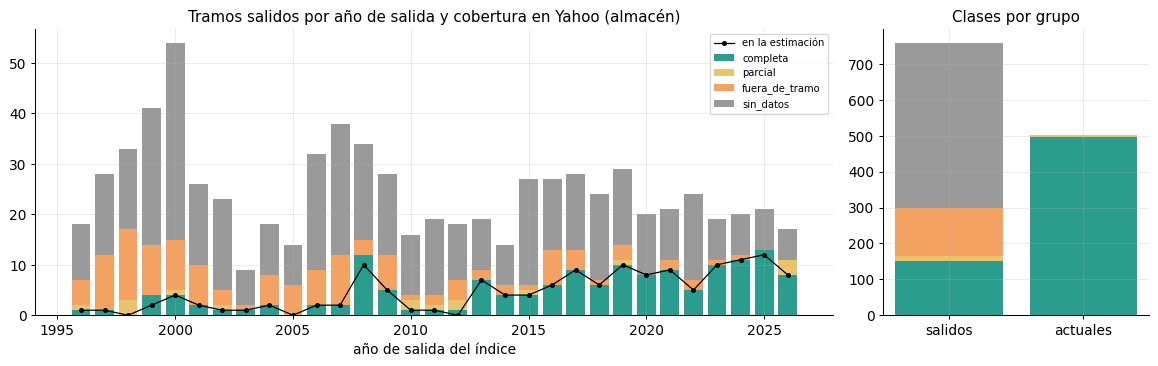

Salidos por clase: {'completa': 150, 'parcial': 16, 'fuera_de_tramo': 134, 'sin_datos': 459}
Actuales por clase: {'completa': 496, 'parcial': 7, 'fuera_de_tramo': 0, 'sin_datos': 0}


In [2]:
s = COB[COB['grupo'] == 'salido'].copy()
s['anio_salida'] = s['anio_salida'].astype(int)
t = s.pivot_table(index='anio_salida', columns='clase', values='ticker', aggfunc='size', fill_value=0)
t = t.reindex(columns=list(sv.CLASES), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [3, 1]})
abajo = np.zeros(len(t))
for c in t.columns:
    axes[0].bar(t.index, t[c], bottom=abajo, color=COLORES[c], label=c)
    abajo += t[c].to_numpy()
usados = s.groupby('anio_salida')['en_estimacion'].sum().reindex(t.index, fill_value=0)
axes[0].plot(t.index, usados, color='k', marker='o', ms=3, lw=1, label='en la estimación')
axes[0].set_title('Tramos salidos por año de salida y cobertura en Yahoo (almacén)')
axes[0].set_xlabel('año de salida del índice')
axes[0].legend(fontsize=8)
grupos = ('salido', 'actual')
izq = np.zeros(2)
for c in sv.CLASES:
    v = np.array([(COB[COB['grupo'] == g]['clase'] == c).sum() for g in grupos])
    axes[1].bar(['salidos', 'actuales'], v, bottom=izq, color=COLORES[c])
    izq += v
axes[1].set_title('Clases por grupo')
plt.tight_layout()
plt.show()
print('Salidos por clase:', MED['salidos_por_clase'])
print('Actuales por clase:', MED['actuales_por_clase'])

Por década de salida (metadatos: tramos, con parquet, con precio dentro del tramo, sospechosos excluidos, en la
estimación; `fraccion_media` = media de la fracción de sesiones con precio; `fraccion_media_util` = la misma contando
como 0 los excluidos):

In [3]:
pd.DataFrame(MED['salidos_por_decada_de_salida']).T

,n,con_fichero,con_precio_en_tramo,completa,sospechosos_excluidos,en_estimacion,fraccion_media,fraccion_media_util
1996-1999,120.0,50.0,10.0,6.0,6.0,4.0,0.068,0.033
2000-2009,276.0,94.0,33.0,31.0,4.0,29.0,0.115,0.105
2010-2019,221.0,83.0,56.0,49.0,8.0,48.0,0.238,0.217
2020-2026,142.0,73.0,67.0,64.0,4.0,63.0,0.451,0.444


## 2. Fracción de sesiones con precio dentro del tramo y sospechas

Cada punto es un tramo salido con precio en algún momento. Las cruces son tramos con **sospecha** de que el precio es
de otra empresa con el mismo ticker, que salen de la estimación principal:

- `empieza_tarde`: el precio empieza más de 31 días después del alta;
- `impropio_sp500`: mediana del cierre < 1 USD o del efectivo diario < 1 M USD dentro del tramo (OTC, ADR o la
  empresa que heredó el ticker);
- `ticker_q`: sufijo Q/QQ de quiebra posterior al tramo con precio dentro.

`termina_tarde` (nota de varios tramos o sufijo Q y precio que sigue más de un año después de la baja) se marca pero
solo la excluye la variante **estricta**: casi siempre es una reentrada de la misma empresa, con la serie empezando
antes del alta. `reutilizado_despues` es informativa (el tramo ya no tiene precio).

C:\Users\Usuario\AppData\Local\Temp\ipykernel_9364\2523159344.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  p['excluido'] = p['clase'].isin(['completa', 'parcial']) & ~p['en_estimacion']


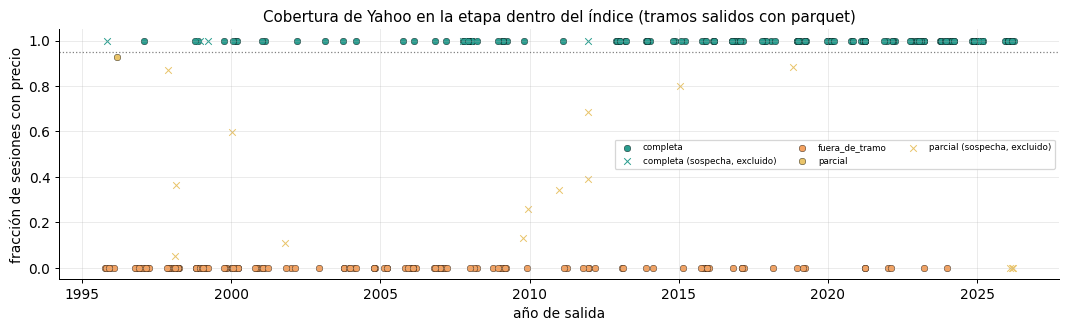

Sospechas (todos los tramos): {'empieza_tarde': 22, 'termina_tarde': 32, 'ticker_q': 0, 'impropio_sp500': 15, 'reutilizado_despues': 134}


In [4]:
fig, ax = plt.subplots(figsize=(12, 3.8))
rng = np.random.default_rng(0)
p = s[s['primera_yahoo'].notna()]
p['excluido'] = p['clase'].isin(['completa', 'parcial']) & ~p['en_estimacion']
for c, g in p.groupby('clase'):
    for excl, marca in ((False, 'o'), (True, 'x')):
        h = g[g['excluido'] == excl]
        if len(h):
            ax.scatter(h['anio_salida'] + rng.uniform(-0.25, 0.25, len(h)), h['fraccion'], color=COLORES[c],
                       marker=marca, s=28, lw=0.8 if marca == 'x' else 0.3,
                       edgecolor='k' if marca == 'o' else None,
                       label=f"{c}{' (sospecha, excluido)' if excl else ''}")
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel('fracción de sesiones con precio')
ax.set_xlabel('año de salida')
ax.axhline(sv.UMBRAL_COMPLETA, color='grey', ls=':', lw=1)
ax.legend(fontsize=7, ncol=3)
ax.set_title('Cobertura de Yahoo en la etapa dentro del índice (tramos salidos con parquet)')
plt.tight_layout()
plt.show()
print('Sospechas (todos los tramos):', MED['sospechas'])

## 3. Sesgo: cartera point-in-time frente a supervivientes

- **PIT con precio**: cada mes, los miembros vigentes el primer día; la media de los salidos con precio y la de los
  actuales con precio se ponderan por cuántos miembros de cada grupo había ese mes (los salidos con precio
  representan a todos los salidos).
- **Supervivientes**: los miembros actuales con precio, con todos sus meses (la composición de hoy aplicada hacia
  atrás, el error típico de un backtest con la lista actual).

**Limitación declarada**: los salidos sin precio (quiebras, compras, tickers reutilizados) no entran en la PIT y son
los peores, así que la diferencia medida es una **cota inferior** del sesgo. Solo hay precio para unos dos tercios de
los miembros PIT de cada mes (`cobertura_pit`), y mucho menos en los noventa.

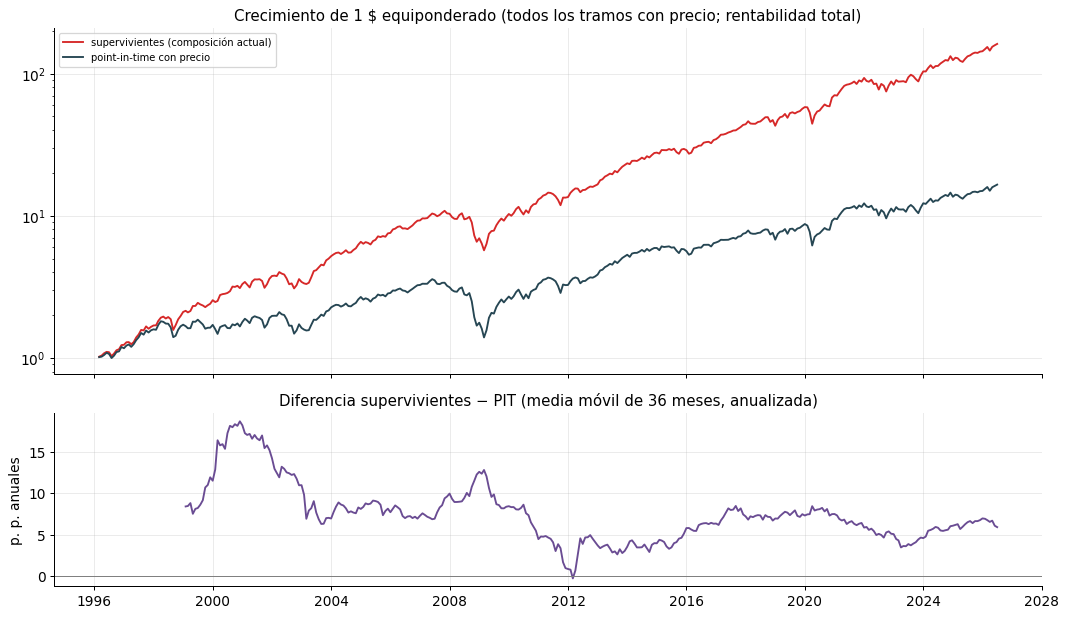

{'meses': 365, 'desde': '1996-02-29', 'hasta': '2026-06-30', 'pit_anual_pct': 10.93, 'supervivientes_anual_pct': 18.2, 'sesgo_anual_pct': 7.28, 'sesgo_ic95_anual_pct': [5.74, 8.81], 'sesgo_t': 9.31, 'cobertura_pit_media': 0.662}


In [5]:
S = SESGO.dropna(subset=['pit', 'supervivientes'])
S = S[~S['pit_solo_actuales']].set_index('mes')
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for col, color, nombre in (('supervivientes', '#d62828', 'supervivientes (composición actual)'),
                           ('pit', '#264653', 'point-in-time con precio')):
    axes[0].plot(S.index, (1 + S[col]).cumprod(), color=color, label=nombre)
axes[0].set_yscale('log')
axes[0].set_title('Crecimiento de 1 $ equiponderado (todos los tramos con precio; rentabilidad total)')
axes[0].legend(fontsize=8)
axes[1].plot(S.index, S['diferencia'].rolling(36).mean() * 1200, color='#6a4c93')
axes[1].axhline(0, color='grey', lw=0.8)
axes[1].set_ylabel('p. p. anuales')
axes[1].set_title('Diferencia supervivientes − PIT (media móvil de 36 meses, anualizada)')
axes[1].xaxis.set_major_locator(mdates.YearLocator(4))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.show()
print({k: v for k, v in MED['sesgo'].items() if k != 'limitacion'})

Variantes de contraste (intervalo al 95 % normal sobre la diferencia mensual, sin corregir autocorrelación):
`sin_sospechas` es la principal; `estricta` excluye además `termina_tarde`; `con_sospechas` mete todos los tramos con
precio dentro del tramo (muestra el daño de no filtrar: unos pocos tickers de otra empresa con rentabilidades
absurdas dominan la media); `muestra_122` es la estimación anterior, con la muestra descargada aparte (su
`cobertura_pit` no es comparable: mide la fracción muestreada, no la cubierta).

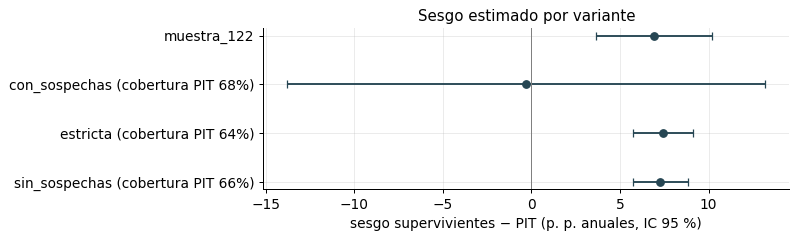

sin_sospechas: 7.28 p. p. [5.74, 8.81], t = 9.31, 365 meses
estricta: 7.43 p. p. [5.73, 9.13], t = 8.57, 365 meses
con_sospechas: -0.29 p. p. [-13.78, 13.2], t = -0.04, 365 meses
muestra_122: 6.91 p. p. [3.66, 10.16], t = 4.17, 362 meses


In [6]:
v = pd.DataFrame(MED['sesgo_variantes']).T
fig, ax = plt.subplots(figsize=(9, 2.8))
y = np.arange(len(v))
lo = v['sesgo_ic95_anual_pct'].str[0].astype(float)
hi = v['sesgo_ic95_anual_pct'].str[1].astype(float)
ax.errorbar(v['sesgo_anual_pct'].astype(float), y, xerr=[v['sesgo_anual_pct'] - lo, hi - v['sesgo_anual_pct']],
            fmt='o', color='#264653', capsize=3)
ax.axvline(0, color='grey', lw=0.8)
ax.set_yticks(y, [k if k == 'muestra_122' else f"{k} (cobertura PIT {c:.0%})"
                  for k, c in zip(v.index, v['cobertura_pit_media'])])
ax.set_xlabel('sesgo supervivientes − PIT (p. p. anuales, IC 95 %)')
ax.set_title('Sesgo estimado por variante')
plt.tight_layout()
plt.show()
for k, r in MED['sesgo_variantes'].items():
    print(f"{k}: {r['sesgo_anual_pct']} p. p. [{r['sesgo_ic95_anual_pct'][0]}, {r['sesgo_ic95_anual_pct'][1]}], "
          f"t = {r['sesgo_t']}, {r['meses']} meses")

¿Cuántos miembros tienen precio cada mes? Si no queda ningún salido con precio, la PIT de ese mes se calcula solo
con los actuales y no cuenta para el sesgo.

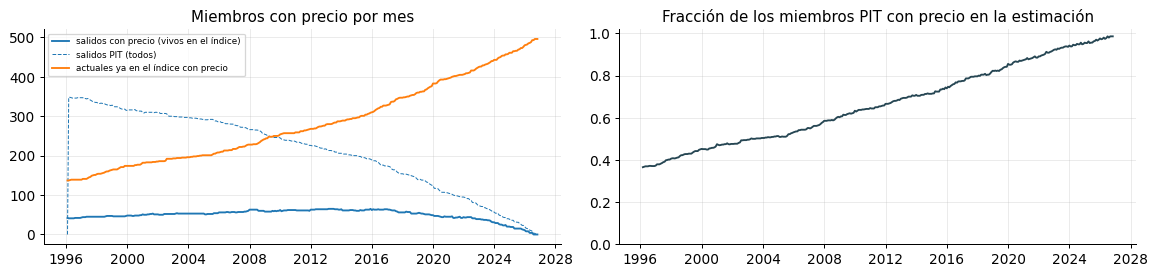

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
M = SESGO.set_index('mes')
axes[0].plot(M.index, M['muestra_salidos_con_precio'], label='salidos con precio (vivos en el índice)')
axes[0].plot(M.index, M['n_salidos_pit'], ls='--', color='C0', lw=0.8, label='salidos PIT (todos)')
axes[0].plot(M.index, M['muestra_actuales_pit_con_precio'], label='actuales ya en el índice con precio')
axes[0].legend(fontsize=7)
axes[0].set_title('Miembros con precio por mes')
axes[1].plot(M.index, M['cobertura_pit'], color='#264653')
axes[1].set_ylim(0, 1.02)
axes[1].set_title('Fracción de los miembros PIT con precio en la estimación')
plt.tight_layout()
plt.show()

## 4. Opciones de corrección

Ninguna fuente gratuita y sin cuenta da precios de deslistados. Decisión vigente: **WRDS/CRSP pendiente de MIAX**;
mientras tanto el sesgo se declara y se mide con esta cota. Alternativas documentadas en la ficha `supervivencia`:

In [8]:
for k, v in sv.OPCIONES_CORRECCION.items():
    print(f'- {k}: {v}')

- wrds_crsp: CRSP vía WRDS: precios y rentabilidades de deslistados (PERMNO, DLRET); pendiente de la licencia de MIAX. Es la corrección completa.
- alpha_vantage_listing_status: Alpha Vantage LISTING_STATUS (state=delisted): solo la LISTA de deslistados con fechas, sin precios. Sirve para identificar, no para corregir rentabilidades.
- tiingo: Tiingo EOD incluye muchos deslistados, pero exige una cuenta (y clave) del usuario; plan gratuito con límites diarios. No se ha probado aquí.
- imputacion_delisting: Sin precios: imputar la rentabilidad de salida (p. ej. -30 % en bajas por quiebra, Shumway 1997) solo como análisis de sensibilidad, declarado.


## Conclusiones

- Con todos los tramos la cobertura de los salidos sigue dependiendo de la década de salida (sección 1): las salidas
  de los noventa y los dos mil casi no tienen precio, y muchos ficheros que existen son de otra empresa con el mismo
  ticker (fuera de tramo o sospechosos); las salidas recientes suelen seguir cotizando.
- El sesgo supervivientes − PIT con precio (sección 3) es del mismo orden que con la muestra de 122 tramos, con un
  intervalo bastante más estrecho; como faltan justo los peores, el sesgo real es mayor que el medido.
- Filtrar los tickers reutilizados es imprescindible: sin filtro la estimación se rompe.
- Para los agentes: los backtests de selección de acciones del S&P 500 con Yahoo **no** son válidos sin corrección;
  los de ETF e índices (el universo invertible del TFM) no tienen este problema. Las cifras están en la ficha
  `supervivencia`.